### Duplicate and Conflicting-Label Sensitivity Analysis
## Purpose

Notebook 1 compared traditional machine learning and deep learning on the original diabetes health-indicators dataset. In this follow-up sensitivity study, we examine whether results change when we remove two types of records that can complicate model learning:

1. **Exact duplicate rows:** records identical across all predictors and the target.
2. **Conflicting-label predictor patterns:** records with exactly the same predictor values but different target labels.

For the second category, we remove **all rows belonging to any conflicting predictor pattern** rather than arbitrarily choosing one of its labels. Then remove exact duplicate rows from each partition and retrain only the two selected models:

- **Traditional ML:** Balanced Random Forest (Experiment 3)
- **Deep learning:** Deeper MLP with focal loss (Experiment 13)

I will retain the group-based train/validation/test split from Notebook 1 so identical predictor patterns are not distributed across partitions. Then evaluate the original saved models on the same cleaned test partition to help distinguish the effect of data cleaning from the effect of retraining.

This is a sensitivity analysis, not a replacement for the original experiments. Removing conflicting-label patterns may reduce label ambiguity, but it may also remove genuine observations and change the data distribution. I will report the actual effect rather than assuming cleaning improves performance. The test set will not be used to tune model settings.


## Research question

**How does removing exact duplicate rows and predictor patterns with conflicting target labels affect the performance and class-specific errors of the selected Random Forest and deeper MLP?**

We will focus on macro F1, prediabetes precision and recall, diabetes recall, confusion matrices, ROC-AUC, and average precision. A conflicting-label pattern means that two or more records have identical predictor values but different `Diabetes_012` labels. I will exclude the whole predictor pattern, not choose a label for it, because the available features do not tell us which conflicting label is correct. This is a transparent data-cleaning decision whose impact will be measured as part of the sensitivity study.


## Load the dataset and configure the notebook

`DATA_PATH` to the same CSV file path that worked in Notebook 1. Use a relativepath if the CSV is in the same project folder, or an absolute path if it is stored elsewhere.

In [3]:
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wandb
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)

In [4]:
DATA_PATH = Path("data/diabetes_012_health_indicators_BRFSS2015.csv")

RANDOM_STATE = 42
TARGET = "Diabetes_012"
CLASS_LABELS = [0, 1, 2]
CLASS_NAMES = ["No diabetes", "Prediabetes", "Diabetes"]
BATCH_SIZE = 512
MAX_EPOCHS = 30
WANDB_PROJECT = "diabetes-health-indicators"
WANDB_MODE = "offline"

RESULTS_DIR = Path("results_deduplication")
MODELS_DIR = Path("saved_models_deduplicated")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}\n"
        "Update DATA_PATH to the same working CSV location used in Notebook 1."
    )

data = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset path:", DATA_PATH.resolve())
print("Original dataset shape:", data.shape)
print("Target column present:", TARGET in data.columns)
print("Missing values in dataset:", int(data.isna().sum().sum()))

Dataset loaded successfully.
Dataset path: /home/janviere-munezero/Documents/ML/Introduction to ML/diabetes-risk-prediction/data/diabetes_012_health_indicators_BRFSS2015.csv
Original dataset shape: (253680, 22)
Target column present: True
Missing values in dataset: 0


**Interpretation:** The dataset loaded successfully with 253,680 records and 22 columns. No missing values were detected. This provides a valid starting point for investigating duplicate records and conflicting labels before retraining the models.

## Audit exact duplicates, conflicting labels, and class balance

Before changing the data, Lets frst count exact duplicate rows and identify predictor patterns that appear with more than one target label. These are different issues: exact duplicates match across both features and label, while conflicting-label patterns match on all features but have different labels.

For this experiment, I will remove all rows belonging to conflicting label predictor patterns first, then remove exact duplicates from the remaining records. The table below compares class counts and percentages before cleaning, after conflicting-pattern removal, and after both cleaning steps. I will not assume that removing these records improves performance; that must be tested.


In [5]:
# Audit exact duplicates and predictor patterns with conflicting target labels.
exact_duplicate_count_original = int(data.duplicated().sum())

X_audit = data.drop(columns=[TARGET])
# Assign one ID to each distinct predictor pattern; target is deliberately excluded.
predictor_group_ids = X_audit.groupby(
    X_audit.columns.tolist(), dropna=False, sort=False
).ngroup().to_numpy()

label_counts_by_group = (
    pd.DataFrame({
        "predictor_group_id": predictor_group_ids,
        "target": data[TARGET].to_numpy(),
    })
    .groupby("predictor_group_id")["target"]
    .nunique()
)
conflicting_group_ids = set(
    label_counts_by_group[label_counts_by_group > 1].index.astype(int)
)
conflicting_mask = np.isin(
    predictor_group_ids, list(conflicting_group_ids)
)
conflicting_pattern_count = len(conflicting_group_ids)
conflicting_row_count = int(conflicting_mask.sum())

# Exclude every row in a conflicting-label predictor pattern.
data_without_conflicts = data.loc[~conflicting_mask].copy()

# Then remove exact duplicate rows among the records that remain.
exact_duplicates_after_conflict_removal = int(
    data_without_conflicts.duplicated().sum()
)
data_clean_for_audit = data_without_conflicts.drop_duplicates().copy()

print("Original dataset shape:", data.shape)
print("Exact duplicate rows in original dataset:", exact_duplicate_count_original)
print("Conflicting predictor patterns:", conflicting_pattern_count)
print("Rows belonging to conflicting predictor patterns:", conflicting_row_count)
print("Exact duplicate rows remaining after excluding conflicting patterns:",
      exact_duplicates_after_conflict_removal)
print("Final shape after both cleaning steps:", data_clean_for_audit.shape)
print("Total rows removed by the two cleaning steps:",
      len(data) - len(data_clean_for_audit))

Original dataset shape: (253680, 22)
Exact duplicate rows in original dataset: 23899
Conflicting predictor patterns: 1834
Rows belonging to conflicting predictor patterns: 6120
Exact duplicate rows remaining after excluding conflicting patterns: 21486
Final shape after both cleaning steps: (226074, 22)
Total rows removed by the two cleaning steps: 27606


In [6]:
# Comparing class counts and percentages through each stage.
stages = {
    "Original": data,
    "After removing conflicting-label patterns": data_without_conflicts,
    "After also removing exact duplicates": data_clean_for_audit,
}
comparison_parts = []
for stage_name, stage_data in stages.items():
    counts = stage_data[TARGET].value_counts().reindex(CLASS_LABELS, fill_value=0)
    percentages = counts / max(len(stage_data), 1) * 100
    comparison_parts.append(pd.DataFrame({
        "Stage": stage_name,
        "Class": CLASS_NAMES,
        "Count": counts.to_numpy(),
        "Percentage": percentages.to_numpy(),
    }))

class_comparison = pd.concat(comparison_parts, ignore_index=True)
display(class_comparison.round(2))

print()
print("Expected audit reference from Notebook 1: roughly 1,834 conflicting predictor patterns across 6,120 rows.")
print("Treat the counts printed above as authoritative if they differ, and verify that the intended CSV was loaded.")


,Stage,Class,Count,Percentage
0,Original,No diabetes,213703,84.24
1,Original,Prediabetes,4631,1.83
2,Original,Diabetes,35346,13.93
3,After removing conflicting-label patterns,No diabetes,209607,84.67
4,After removing conflicting-label patterns,Prediabetes,4293,1.73
5,After removing conflicting-label patterns,Diabetes,33660,13.60
6,After also removing exact duplicates,No diabetes,188251,83.27
7,After also removing exact duplicates,Prediabetes,4292,1.90
8,After also removing exact duplicates,Diabetes,33531,14.83



Expected audit reference from Notebook 1: roughly 1,834 conflicting predictor patterns across 6,120 rows.
Treat the counts printed above as authoritative if they differ, and verify that the intended CSV was loaded.


**Interpretation:** The audit identified 23,899 exact duplicate rows and 1,834 conflicting predictor patterns involving 6,120 records. Removing conflicting-label patterns first, followed by exact duplicates, reduced the dataset from 253,680 to 226,074 records a reduction of 27,606 rows. The class distribution also changed, demonstrating why data-cleaning decisions may affect model performance. Removing conflicting patterns is a sensitivity-analysis choice because differing labels do not necessarily mean the records are incorrect.


## Reproduce the group-based split, then clean each partition

First reproduce Notebook 1's two-stage `GroupShuffleSplit` on the original rows using the same random seed. Group IDs are built from predictor values only, so identical predictor patterns cannot cross between training, validation, and test partitions.

After the split, remove every row whose predictor pattern had conflicting target labels anywhere in the original dataset. Because each predictor group belongs to only one partition, the full conflicting pattern is removed from that partition, then remove exact duplicate rows within each cleaned partition.

This preserves the original split-assignment procedure while ensuring that the models are trained and evaluated on records without exact duplicates or the identified conflicting-label patterns. The resulting partitions will be smaller than Notebook 1's partitions; that is expected. We will verify that the group-overlap checks remain zero.


In [7]:
# Separate original predictors and target.
X_all = data.drop(columns=[TARGET])
y_all = data[TARGET].astype(int)

# Using the predictor-group IDs already computed in the audit cell.
group_ids = predictor_group_ids

# Splitting training and validation versus test (approximately 85% / 15%).
test_splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=RANDOM_STATE
)
train_val_idx, test_idx = next(
    test_splitter.split(X_all, y_all, groups=group_ids)
)

# SPlitting training versus validation, so validation is approximately 15% of all rows.
val_splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.15 / 0.85, random_state=RANDOM_STATE
)
train_rel_idx, val_rel_idx = next(
    val_splitter.split(
        X_all.iloc[train_val_idx],
        y_all.iloc[train_val_idx],
        groups=group_ids[train_val_idx],
    )
)
train_idx = train_val_idx[train_rel_idx]
val_idx = train_val_idx[val_rel_idx]

# Original partitions before the two cleaning steps.
train_raw = data.iloc[train_idx].copy()
val_raw = data.iloc[val_idx].copy()
test_raw = data.iloc[test_idx].copy()

# removing conflicting-label groups, then exact duplicates.
def clean_partition(indices):
    partition = data.iloc[indices].copy()
    partition["__predictor_group_id__"] = group_ids[indices]

    conflicting_here = partition["__predictor_group_id__"].isin(
        conflicting_group_ids
    )
    conflicting_rows_removed = int(conflicting_here.sum())
    partition = partition.loc[~conflicting_here].drop(
        columns=["__predictor_group_id__"]
    )

    rows_before_exact_deduplication = len(partition)
    partition = partition.drop_duplicates().copy()
    exact_duplicates_removed = rows_before_exact_deduplication - len(partition)

    return partition, conflicting_rows_removed, exact_duplicates_removed

train_dedup, train_conflicts_removed, train_exact_duplicates_removed = clean_partition(train_idx)
val_dedup, val_conflicts_removed, val_exact_duplicates_removed = clean_partition(val_idx)
test_dedup, test_conflicts_removed, test_exact_duplicates_removed = clean_partition(test_idx)

print("Original split sizes before cleaning:")
print("Train:", train_raw.shape, "Validation:", val_raw.shape, "Test:", test_raw.shape)
print("Reference sizes from Notebook 1 were approximately: train 177251, validation 38203, test 38226.")

print()
print("Rows removed because their predictor pattern had conflicting labels:")
print("Train:", train_conflicts_removed)
print("Validation:", val_conflicts_removed)
print("Test:", test_conflicts_removed)

print()
print("Exact duplicate rows removed after conflicting patterns were excluded:")
print("Train:", train_exact_duplicates_removed)
print("Validation:", val_exact_duplicates_removed)
print("Test:", test_exact_duplicates_removed)

print()
print("Final cleaned split sizes:")
print("Train:", train_dedup.shape, "Validation:", val_dedup.shape, "Test:", test_dedup.shape)
print("Total rows removed:",
      (len(data) - len(train_dedup) - len(val_dedup) - len(test_dedup)))



Original split sizes before cleaning:
Train: (177251, 22) Validation: (38203, 22) Test: (38226, 22)
Reference sizes from Notebook 1 were approximately: train 177251, validation 38203, test 38226.

Rows removed because their predictor pattern had conflicting labels:
Train: 4314
Validation: 949
Test: 857

Exact duplicate rows removed after conflicting patterns were excluded:
Train: 14707
Validation: 3338
Test: 3441

Final cleaned split sizes:
Train: (158230, 22) Validation: (33916, 22) Test: (33928, 22)
Total rows removed: 27606


In [8]:
# Prepare predictors and targets for model development.
X_train_dedup = train_dedup.drop(columns=[TARGET])
y_train_dedup = train_dedup[TARGET].astype(int)
X_val_dedup = val_dedup.drop(columns=[TARGET])
y_val_dedup = val_dedup[TARGET].astype(int)
X_test_dedup = test_dedup.drop(columns=[TARGET])
y_test_dedup = test_dedup[TARGET].astype(int)

# Verify no predictor group overlaps between the original partitions.
# This check is about split integrity, not the later removal process.
train_groups = set(group_ids[train_idx])
val_groups = set(group_ids[val_idx])
test_groups = set(group_ids[test_idx])

print()
print("Original predictor-group overlap checks (all should be zero):")
print("Train–validation:", len(train_groups & val_groups))
print("Train–test:", len(train_groups & test_groups))
print("Validation–test:", len(val_groups & test_groups))

assert len(train_groups & val_groups) == 0
assert len(train_groups & test_groups) == 0
assert len(val_groups & test_groups) == 0

# Confirm that no conflicting-label predictor patterns or exact duplicate rows remain.
for split_name, split_data in [
    ("Train", train_dedup),
    ("Validation", val_dedup),
    ("Test", test_dedup),
]:
    split_X = split_data.drop(columns=[TARGET])
    split_groups = split_X.groupby(
        split_X.columns.tolist(), dropna=False, sort=False
    ).ngroup()
    group_target_counts = pd.DataFrame({
        "group": split_groups.to_numpy(),
        "target": split_data[TARGET].to_numpy(),
    }).groupby("group")["target"].nunique()
    print(f"{split_name} exact duplicate rows remaining:", int(split_data.duplicated().sum()))
    print(f"{split_name} conflicting predictor patterns remaining:", int((group_target_counts > 1).sum()))

print()
print("Class distributions after both cleaning steps:")
for split_name, target_values in [
    ("Train", y_train_dedup),
    ("Validation", y_val_dedup),
    ("Test", y_test_dedup),
]:
    proportions = target_values.value_counts(normalize=True).reindex(CLASS_LABELS, fill_value=0)
    print(f"{split_name}: {(proportions * 100).round(2).to_dict()}")



Original predictor-group overlap checks (all should be zero):
Train–validation: 0
Train–test: 0
Validation–test: 0
Train exact duplicate rows remaining: 0
Train conflicting predictor patterns remaining: 0
Validation exact duplicate rows remaining: 0
Validation conflicting predictor patterns remaining: 0
Test exact duplicate rows remaining: 0
Test conflicting predictor patterns remaining: 0

Class distributions after both cleaning steps:
Train: {0: 83.27, 1: 1.89, 2: 14.84}
Validation: {0: 83.05, 1: 1.97, 2: 14.98}
Test: {0: 83.49, 1: 1.87, 2: 14.65}


**Interpretation:** The original group-based split was retained before cleaning, and the removed records were tracked separately in each partition. After cleaning, 158,230 training, 33,916 validation, and 33,928 test records remained. All predictor-group overlap checks were zero, and no exact duplicates or conflicting predictor patterns remained in any partition. However, the classes are still imbalanced, so we must continue evaluating macro F1 and class-specific performance rather than accuracy alone.

## Preprocess the cleaned partitions

Here the same feature treatment strategy are used as of Notebook 1: binary features pass through unchanged, while ordinal and numeric features are standardized. The preprocessor is fitted **only on the cleaned training data**, then applied to validation and test data without refitting. This prevents information from validation or test sets from entering preprocessing.


In [9]:
BINARY_FEATURES = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]
ORDINAL_FEATURES = ["GenHlth", "Age", "Education", "Income"]
NUMERIC_FEATURES = ["BMI", "MentHlth", "PhysHlth"]

expected_features = BINARY_FEATURES + ORDINAL_FEATURES + NUMERIC_FEATURES
missing_features = sorted(set(expected_features) - set(X_train_dedup.columns))
if missing_features:
    raise ValueError(f"Expected features missing from dataset: {missing_features}")

preprocessor_dedup = ColumnTransformer(
    transformers=[
        ("binary", "passthrough", BINARY_FEATURES),
        ("scaled", StandardScaler(), ORDINAL_FEATURES + NUMERIC_FEATURES),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_train_dedup_processed = preprocessor_dedup.fit_transform(X_train_dedup)
X_val_dedup_processed = preprocessor_dedup.transform(X_val_dedup)
X_test_dedup_processed = preprocessor_dedup.transform(X_test_dedup)

print("Processed shapes:")
print("Train:", X_train_dedup_processed.shape)
print("Validation:", X_val_dedup_processed.shape)
print("Test:", X_test_dedup_processed.shape)
print("Any non-finite training values:", not np.isfinite(X_train_dedup_processed).all())
print("Any non-finite validation values:", not np.isfinite(X_val_dedup_processed).all())
print("Any non-finite test values:", not np.isfinite(X_test_dedup_processed).all())

Processed shapes:
Train: (158230, 21)
Validation: (33916, 21)
Test: (33928, 21)
Any non-finite training values: False
Any non-finite validation values: False
Any non-finite test values: False


**Interpretation:** Preprocessing produced 21 features for each cleaned partition, with no non-finite values detected. The training, validation, and test sets are ready for model training and evaluation. I will fit the two selected models on the cleaned training data, use validation data for model monitoring, and reserve the cleaned test set for final evaluation.

## Define consistent evaluation metrics

The following helper function overall classification metrics and per-class precision, recall, F1, ROC-AUC, and average precision, will use the same helper for validation and test results so the model comparisons are consistent.

In [10]:
def evaluate_probabilities(y_true, probabilities):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities)
    predictions = np.argmax(probabilities, axis=1)

    report = classification_report(
        y_true,
        predictions,
        labels=CLASS_LABELS,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )

    y_binary = label_binarize(y_true, classes=CLASS_LABELS)

    metrics = {
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro F1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, predictions, average="weighted", zero_division=0),
        "Macro Precision": precision_score(y_true, predictions, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, predictions, average="macro", zero_division=0),
        "Macro ROC-AUC": roc_auc_score(
            y_true, probabilities, labels=CLASS_LABELS,
            multi_class="ovr", average="macro"
        ),
    }

    for i, class_name in enumerate(CLASS_NAMES):
        metrics[f"{class_name} Precision"] = report[class_name]["precision"]
        metrics[f"{class_name} Recall"] = report[class_name]["recall"]
        metrics[f"{class_name} F1"] = report[class_name]["f1-score"]
        metrics[f"{class_name} ROC-AUC"] = roc_auc_score(
            y_binary[:, i], probabilities[:, i]
        )
        metrics[f"{class_name} Average Precision"] = average_precision_score(
            y_binary[:, i], probabilities[:, i]
        )

    return metrics, predictions

## Retrain the selected traditional model

Retrain the balanced Random Forest using the same main settings as Experiment 3, but on the training partition after removing conflicting-label predictor patterns and exact duplicate rows. We use the similarly cleaned validation partition for evaluation. The run logs the configuration, training time, and validation metrics.


In [11]:
rf_dedup_config = {
    "experiment": "Duplicate and Conflicting-Label Sensitivity - Random Forest",
    "n_estimators": 200,
    "max_depth": None,
    "min_samples_leaf": 2,
    "class_weight": "balanced",
    "random_state": RANDOM_STATE,
    "training_data": "Conflicting-label predictor patterns and exact duplicate rows removed within group-based split",
}

rf_dedup = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_run = wandb.init(
    project=WANDB_PROJECT,
    name="Cleaning Sensitivity - Balanced Random Forest",
    mode=WANDB_MODE,
    config=rf_dedup_config,
)
try:
    start_time = time.time()
    rf_dedup.fit(X_train_dedup_processed, y_train_dedup)
    rf_training_seconds = time.time() - start_time

    rf_val_prob = rf_dedup.predict_proba(X_val_dedup_processed)
    rf_val_prob = rf_val_prob[:, [list(rf_dedup.classes_).index(c) for c in CLASS_LABELS]]
    rf_val_metrics, rf_val_pred = evaluate_probabilities(y_val_dedup, rf_val_prob)

    rf_log = {f"validation/{k.lower().replace(' ', '_')}": float(v)
              for k, v in rf_val_metrics.items()}
    rf_log["training_seconds"] = float(rf_training_seconds)
    wandb.log(rf_log)
    rf_run.summary["validation_macro_f1"] = float(rf_val_metrics["Macro F1"])
    rf_run.summary["training_seconds"] = float(rf_training_seconds)

    print(f"Training time: {rf_training_seconds:.2f} seconds")
    display(pd.DataFrame([rf_val_metrics], index=["Deduplicated Random Forest"]).round(4))
finally:
    wandb.finish()

pd.DataFrame([rf_val_metrics]).to_csv(
    RESULTS_DIR / "cleaned_random_forest_validation_metrics.csv", index=False
)

Training time: 30.19 seconds


,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC,No diabetes Precision,No diabetes Recall,No diabetes F1,No diabetes ROC-AUC,...,Prediabetes Precision,Prediabetes Recall,Prediabetes F1,Prediabetes ROC-AUC,Prediabetes Average Precision,Diabetes Precision,Diabetes Recall,Diabetes F1,Diabetes ROC-AUC,Diabetes Average Precision
Deduplicated Random Forest,0.7535,0.4421,0.7737,0.4339,0.4895,0.7537,0.9196,0.7855,0.8473,0.8115,...,0.0263,0.009,0.0134,0.634,0.0297,0.3556,0.6741,0.4656,0.8154,0.4229


training_seconds,▁
validation/accuracy,▁
validation/diabetes_average_precision,▁
validation/diabetes_f1,▁
validation/diabetes_precision,▁
validation/diabetes_recall,▁
validation/diabetes_roc-auc,▁
validation/macro_f1,▁
validation/macro_precision,▁
validation/macro_recall,▁
+12,...


## Retrain the deeper MLP with focal loss

Retrain the Experiment 13 architecture (256, 128, and 64 neurons), with dropout, Adam at a learning rate of 0.001, and focal loss with gamma 2.0. The inverse-square-root class weights are recalculated from the cleaned training set. Both exact duplicates and entire predictor patterns with conflicting labels have been excluded. Early stopping and learning-rate reduction help avoid unnecessary training. Training history and validation metrics are logged in one W&B run.


In [12]:
# Prepare TensorFlow arrays and tf.data datasets.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

X_train_dl_dedup = np.asarray(X_train_dedup_processed, dtype=np.float32)
X_val_dl_dedup = np.asarray(X_val_dedup_processed, dtype=np.float32)
y_train_dl_dedup = np.asarray(y_train_dedup, dtype=np.int32)
y_val_dl_dedup = np.asarray(y_val_dedup, dtype=np.int32)

counts = np.bincount(y_train_dl_dedup, minlength=3)
frequencies = counts / counts.sum()
sqrt_weights = 1.0 / np.sqrt(frequencies)
sqrt_weights = sqrt_weights / sqrt_weights.mean()
sqrt_class_weight_dedup = {i: float(w) for i, w in enumerate(sqrt_weights)}

print("Deduplicated training counts:", counts.tolist())
print("Recalculated focal-loss class weights:", sqrt_class_weight_dedup)

train_ds_dedup = (
    tf.data.Dataset.from_tensor_slices((X_train_dl_dedup, y_train_dl_dedup))
    .shuffle(buffer_size=min(len(y_train_dl_dedup), 50000),
             seed=RANDOM_STATE, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(1)
)
val_ds_dedup = (
    tf.data.Dataset.from_tensor_slices((X_val_dl_dedup, y_val_dl_dedup))
    .batch(BATCH_SIZE)
    .prefetch(1)
)


def make_focal_loss(class_weights, gamma=2.0):
    alpha = tf.constant([class_weights[i] for i in CLASS_LABELS], dtype=tf.float32)

    def focal_loss(y_true, y_pred):
        y_true_flat = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        one_hot = tf.one_hot(y_true_flat, depth=3)
        true_probability = tf.reduce_sum(one_hot * y_pred, axis=1)
        alpha_factor = tf.reduce_sum(one_hot * alpha, axis=1)
        losses = -alpha_factor * tf.pow(1.0 - true_probability, gamma) * tf.math.log(true_probability)
        return tf.reduce_mean(losses)

    return focal_loss

mlp_dedup = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_dl_dedup.shape[1],)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(3, activation="softmax"),
])

mlp_dedup.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=make_focal_loss(sqrt_class_weight_dedup, gamma=2.0),
    metrics=["accuracy"],
)

mlp_dedup_config = {
    "experiment": "Duplicate and Conflicting-Label Sensitivity - Deeper MLP with Focal Loss",
    "hidden_layers": [256, 128, 64],
    "dropout_rates": [0.3, 0.3, 0.2],
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "Focal Loss",
    "focal_gamma": 2.0,
    "class_weight_strategy": "normalized inverse square-root frequencies from deduplicated training set",
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "random_state": RANDOM_STATE,
}

class WandbEpochLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        log_values = {
            f"epoch/{key}": float(value)
            for key, value in logs.items()
            if value is not None
        }
        log_values["epoch/number"] = epoch + 1
        wandb.log(log_values)

mlp_run = wandb.init(
    project=WANDB_PROJECT,
    name="Cleaning Sensitivity - Deeper MLP Focal Loss",
    mode=WANDB_MODE,
    config=mlp_dedup_config,
)
try:
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2,
            min_lr=1e-6, verbose=1
        ),
        WandbEpochLogger(),
    ]

    mlp_history_dedup = mlp_dedup.fit(
        train_ds_dedup,
        validation_data=val_ds_dedup,
        epochs=MAX_EPOCHS,
        callbacks=callbacks,
        verbose=1,
        shuffle=False,
    )

    mlp_val_prob = mlp_dedup.predict(X_val_dl_dedup, verbose=0)
    mlp_val_metrics, mlp_val_pred = evaluate_probabilities(y_val_dl_dedup, mlp_val_prob)

    mlp_log = {f"validation/{k.lower().replace(' ', '_')}": float(v)
               for k, v in mlp_val_metrics.items()}
    mlp_log["best_epoch"] = int(np.argmin(mlp_history_dedup.history["val_loss"]) + 1)
    mlp_log["best_validation_loss"] = float(min(mlp_history_dedup.history["val_loss"]))
    wandb.log(mlp_log)

    mlp_run.summary["best_epoch"] = mlp_log["best_epoch"]
    mlp_run.summary["best_validation_loss"] = mlp_log["best_validation_loss"]
    display(pd.DataFrame([mlp_val_metrics], index=["Deduplicated Deeper MLP"]).round(4))
finally:
    wandb.finish()

pd.DataFrame(mlp_history_dedup.history).to_csv(
    RESULTS_DIR / "cleaned_mlp_training_history.csv", index=False
)
pd.DataFrame([mlp_val_metrics]).to_csv(
    RESULTS_DIR / "cleaned_mlp_validation_metrics.csv", index=False
)

Deduplicated training counts: [131760, 2990, 23480]
Recalculated focal-loss class weights: {0: 0.2997851156411709, 1: 1.990060433880445, 2: 0.7101544504783838}


E0000 00:00:1792329295.775584   31768 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/30
310/310 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - accuracy: 0.7944 - loss: 0.1255 - val_accuracy: 0.8143 - val_loss: 0.1226 - learning_rate: 0.0010
Epoch 2/30
310/310 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.8057 - loss: 0.1213 - val_accuracy: 0.8086 - val_loss: 0.1207 - learning_rate: 0.0010
Epoch 3/30
310/310 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.8064 - loss: 0.1203 - val_accuracy: 0.8084 - val_loss: 0.1211 - learning_rate: 0.0010
Epoch 4/30
309/310 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8074 - loss: 0.1194
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
310/310 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.8074 - loss: 0.1194 - val_accuracy: 0.8093 - val_loss: 0.1207 - learning_rate: 0.0010
Epoch 5/30
310/310 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.8087 - loss: 0.1188 - val_accuracy: 0.8077 - val_loss: 0.1202 - learning_rate: 5.0000e-04
Epoch 6/30
310/310 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.8080 - los

,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC,No diabetes Precision,No diabetes Recall,No diabetes F1,No diabetes ROC-AUC,...,Prediabetes Precision,Prediabetes Recall,Prediabetes F1,Prediabetes ROC-AUC,Prediabetes Average Precision,Diabetes Precision,Diabetes Recall,Diabetes F1,Diabetes ROC-AUC,Diabetes Average Precision
Deduplicated Deeper MLP,0.8077,0.4533,0.8075,0.4403,0.4712,0.7701,0.8987,0.8756,0.887,0.8191,...,0.0,0.0,0.0,0.6687,0.0337,0.4221,0.5379,0.473,0.8224,0.4365


best_epoch,▁
best_validation_loss,▁
epoch/accuracy,▁▇▇▇████▇
epoch/learning_rate,████▃▃▃▁▁
epoch/loss,█▄▃▃▂▂▂▁▁
epoch/number,▁▂▃▄▅▅▆▇█
epoch/val_accuracy,█▃▃▄▂▅▁▁▁
epoch/val_loss,█▃▄▂▁▁▁▁▁
validation/accuracy,▁
validation/diabetes_average_precision,▁
+19,...


## CCompare validation performance

Before opening the test set, compare the two retrained models using the cleaned validation data. Validation results describe model selection; the test set remains reserved for the final evaluation.

In [13]:
dedup_validation_comparison = pd.DataFrame([
    {"Model": "Balanced Random Forest (cleaned training data)", **rf_val_metrics},
    {"Model": "Deeper MLP with focal loss (cleaned training data)", **mlp_val_metrics},
])

dedup_validation_comparison.to_csv(
    RESULTS_DIR / "cleaned_validation_comparison.csv", index=False
)
display(dedup_validation_comparison.round(4))

,Model,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC,No diabetes Precision,No diabetes Recall,No diabetes F1,...,Prediabetes Precision,Prediabetes Recall,Prediabetes F1,Prediabetes ROC-AUC,Prediabetes Average Precision,Diabetes Precision,Diabetes Recall,Diabetes F1,Diabetes ROC-AUC,Diabetes Average Precision
0,Balanced Random Forest (cleaned training data),0.7535,0.4421,0.7737,0.4339,0.4895,0.7537,0.9196,0.7855,0.8473,...,0.0263,0.009,0.0134,0.6340,0.0297,0.3556,0.6741,0.4656,0.8154,0.4229
1,Deeper MLP with focal loss (cleaned training d...,0.8077,0.4533,0.8075,0.4403,0.4712,0.7701,0.8987,0.8756,0.8870,...,0.0000,0.000,0.0000,0.6687,0.0337,0.4221,0.5379,0.4730,0.8224,0.4365


## Save the sensitivity analysis models and preprocessing

Lets save these models in a separate folder so they do not overwrite the original models from Notebook 1. The saved artifacts include the fitted preprocessing pipeline, complete deep-learning model, separate weights file, and metadata describing both cleaning steps. These artifacts correspond to models trained after excluding conflicting label predictor patterns and exact duplicates.


In [14]:
# Save the cleaned data Random Forest and its preprocessor.
rf_dedup_artifact = {
    "model": rf_dedup,
    "preprocessor": preprocessor_dedup,
    "model_name": "Random Forest (Balanced) - Conflicting Patterns and Exact Duplicates Removed",
    "experiment": "Duplicate and Conflicting-Label Sensitivity Analysis",
    "random_state": RANDOM_STATE,
    "class_names": CLASS_NAMES,
}

rf_dedup_path = MODELS_DIR / "deduplicated_traditional_model.joblib"
joblib.dump(rf_dedup_artifact, rf_dedup_path)

preprocessor_dedup_path = MODELS_DIR / "deduplicated_preprocessor.joblib"
joblib.dump(preprocessor_dedup, preprocessor_dedup_path)

# Save the cleaned data MLP.
mlp_dedup_path = MODELS_DIR / "deduplicated_deep_learning_model.keras"
mlp_dedup_weights_path = MODELS_DIR / "deduplicated_deep_learning_model.weights.h5"
mlp_dedup.save(mlp_dedup_path)
mlp_dedup.save_weights(mlp_dedup_weights_path)

metadata_dedup = {
    "study": "Duplicate and conflicting-label sensitivity analysis",
    "exact_duplicate_definition": "Rows identical across all predictor and target columns",
    "conflicting_label_definition": "Identical predictor patterns associated with more than one target label; all rows in those patterns were excluded",
    "conflicting_predictor_patterns_removed": int(conflicting_pattern_count),
    "rows_in_conflicting_predictor_patterns_removed": int(conflicting_row_count),
    "exact_duplicates_removed_after_conflict_filter": int(exact_duplicates_after_conflict_removal),
    "split_strategy": "GroupShuffleSplit based on predictors, followed by removal of conflicting-label patterns and exact duplicates within each partition",
    "random_state": RANDOM_STATE,
    "training_rows_after_cleaning": int(len(train_dedup)),
    "validation_rows_after_cleaning": int(len(val_dedup)),
    "test_rows_after_cleaning": int(len(test_dedup)),
    "models": ["Balanced Random Forest", "Deeper MLP with focal loss"],
    "test_used_for_tuning": False,
}
metadata_dedup_path = MODELS_DIR / "deduplication_metadata.json"
with open(metadata_dedup_path, "w") as f:
    json.dump(metadata_dedup, f, indent=4)

for saved_path in [rf_dedup_path, preprocessor_dedup_path,
                   mlp_dedup_path, mlp_dedup_weights_path, metadata_dedup_path]:
    print(f"{saved_path}: {'Saved successfully' if saved_path.exists() else 'NOT FOUND'}")

saved_models_deduplicated/deduplicated_traditional_model.joblib: Saved successfully
saved_models_deduplicated/deduplicated_preprocessor.joblib: Saved successfully
saved_models_deduplicated/deduplicated_deep_learning_model.keras: Saved successfully
saved_models_deduplicated/deduplicated_deep_learning_model.weights.h5: Saved successfully
saved_models_deduplicated/deduplication_metadata.json: Saved successfully


## Final evaluation on the cleaned test partition

Lets evaluate the newly retrained models on the cleaned test partition. We also load the original models from Notebook 1 and evaluate them on these same cleaned test examples. This gives four comparable evaluations on one common cleaned test set:

1. Original Random Forest evaluated on the cleaned test examples.
2. Random Forest retrained on the cleaned training partition.
3. Original MLP evaluated on the cleaned test examples.
4. MLP retrained on the cleaned training partition.


In [15]:
# Load original models saved from Notebook 1.
ORIGINAL_MODELS_DIR = Path("saved_models")
original_rf_artifact_path = ORIGINAL_MODELS_DIR / "best_traditional_model.joblib"
original_mlp_path = ORIGINAL_MODELS_DIR / "best_deep_learning_model.keras"

if not original_rf_artifact_path.exists() or not original_mlp_path.exists():
    raise FileNotFoundError(
        "Could not find the original models from Notebook 1. "
        "Ensure this notebook is running from the same project folder, "
        "or update ORIGINAL_MODELS_DIR to the correct folder."
    )

original_rf_artifact = joblib.load(original_rf_artifact_path)
original_rf = original_rf_artifact["model"]
original_preprocessor = original_rf_artifact["preprocessor"]
original_mlp = tf.keras.models.load_model(original_mlp_path, compile=False)

# Transform the same cleaned test records using each model's own fitted preprocessor.
X_test_for_original = original_preprocessor.transform(X_test_dedup)
X_test_for_original_dl = np.asarray(X_test_for_original, dtype=np.float32)
X_test_for_dedup_models = X_test_dedup_processed

# Probabilities from the original saved models on the cleaned test records.
original_rf_prob = original_rf.predict_proba(X_test_for_original)
original_rf_prob = original_rf_prob[:, [list(original_rf.classes_).index(c) for c in CLASS_LABELS]]
original_mlp_prob = original_mlp.predict(X_test_for_original_dl, verbose=0)

# Probabilities from the models retrained on the cleaned training data.
rf_dedup_test_prob = rf_dedup.predict_proba(X_test_for_dedup_models)
rf_dedup_test_prob = rf_dedup_test_prob[:, [list(rf_dedup.classes_).index(c) for c in CLASS_LABELS]]
mlp_dedup_test_prob = mlp_dedup.predict(
    np.asarray(X_test_for_dedup_models, dtype=np.float32), verbose=0
)

# Consistent metrics for all four model evaluations on the same cleaned test set.
test_evaluation_specs = [
    ("Original RF evaluated on cleaned test", original_rf_prob),
    ("Cleaned-data-trained RF on cleaned test", rf_dedup_test_prob),
    ("Original MLP evaluated on cleaned test", original_mlp_prob),
    ("Cleaned-data-trained MLP on cleaned test", mlp_dedup_test_prob),
]

test_result_rows = []
test_predictions = {}
test_probabilities = {}
for model_name, probabilities in test_evaluation_specs:
    metrics, predictions = evaluate_probabilities(y_test_dedup, probabilities)
    test_result_rows.append({"Model evaluation": model_name, **metrics})
    test_predictions[model_name] = predictions
    test_probabilities[model_name] = probabilities

dedup_test_results = pd.DataFrame(test_result_rows)
dedup_test_results.to_csv(
    RESULTS_DIR / "cleaned_test_results.csv", index=False
)
print("Final test results on the same cleaned test partition:")
display(dedup_test_results.round(4))

Final test results on the same cleaned test partition:


,Model evaluation,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC,No diabetes Precision,No diabetes Recall,No diabetes F1,...,Prediabetes Precision,Prediabetes Recall,Prediabetes F1,Prediabetes ROC-AUC,Prediabetes Average Precision,Diabetes Precision,Diabetes Recall,Diabetes F1,Diabetes ROC-AUC,Diabetes Average Precision
0,Original RF evaluated on cleaned test,0.7445,0.4377,0.7693,0.4297,0.4936,0.7529,0.9274,0.7680,0.8402,...,0.0180,0.0079,0.0110,0.6314,0.0263,0.3437,0.7048,0.4620,0.8159,0.4072
1,Cleaned-data-trained RF on cleaned test,0.7560,0.4419,0.7772,0.4330,0.4920,0.7545,0.9238,0.7855,0.8491,...,0.0225,0.0079,0.0117,0.6355,0.0264,0.3526,0.6827,0.4650,0.8155,0.4059
2,Original MLP evaluated on cleaned test,0.8081,0.4529,0.8099,0.4389,0.4737,0.7739,0.9039,0.8715,0.8874,...,0.0000,0.0000,0.0000,0.6747,0.0323,0.4127,0.5495,0.4714,0.8254,0.4295
3,Cleaned-data-trained MLP on cleaned test,0.8099,0.4530,0.8107,0.4395,0.4720,0.7747,0.9024,0.8752,0.8886,...,0.0000,0.0000,0.0000,0.6777,0.0316,0.4162,0.5408,0.4704,0.8245,0.4249


## Compare with Notebook 1 results

This table provides context by placing the original test scores from Notebook 1 alongside the sensitivity results. The original scores came from the original test split with duplicate and conflicting-label patterns retained. The sensitivity models and the re-evaluated original models use the cleaned test partition after those records have been excluded. Because the underlying test examples and class distribution differ, this cross-table comparison is descriptive rather than a perfectly controlled estimate of the cleaning effect. For the fairest comparison, focus first on the original and retrained versions of each model evaluated on the same cleaned test.


In [16]:
original_test_benchmarks = pd.DataFrame([
    {
        "Evaluation": "Notebook 1 - original test split",
        "Model": "Balanced Random Forest (Exp 3)",
        "Accuracy": 0.7612,
        "Macro F1": 0.4419,
        "Weighted F1": 0.7848,
        "Macro Precision": 0.4316,
        "Macro Recall": 0.4951,
        "Macro ROC-AUC": 0.7583,
        "Prediabetes Precision": 0.0222,
        "Prediabetes Recall": 0.0117,
        "Diabetes Recall": 0.6839,
    },
    {
        "Evaluation": "Notebook 1 - original test split",
        "Model": "Deeper MLP (Exp 13)",
        "Accuracy": 0.8215,
        "Macro F1": 0.4536,
        "Weighted F1": 0.8218,
        "Macro Precision": 0.4403,
        "Macro Recall": 0.4719,
        "Macro ROC-AUC": 0.7781,
        "Prediabetes Precision": 0.0000,
        "Prediabetes Recall": 0.0000,
        "Diabetes Recall": 0.5295,
    },
])

sensitivity_cols = [
    "Accuracy", "Macro F1", "Weighted F1", "Macro Precision", "Macro Recall",
    "Macro ROC-AUC", "Prediabetes Precision", "Prediabetes Recall", "Diabetes Recall"
]

current_sensitivity = dedup_test_results[["Model evaluation"] + sensitivity_cols].rename(
    columns={"Model evaluation": "Model"}
)
current_sensitivity.insert(0, "Evaluation", "Sensitivity notebook - cleaned test split")

combined_sensitivity_results = pd.concat(
    [original_test_benchmarks, current_sensitivity], ignore_index=True
)
combined_sensitivity_results.to_csv(
    RESULTS_DIR / "original_vs_cleaned_test_comparison.csv", index=False
)
display(combined_sensitivity_results.round(4))

,Evaluation,Model,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC,Prediabetes Precision,Prediabetes Recall,Diabetes Recall
0,Notebook 1 - original test split,Balanced Random Forest (Exp 3),0.7612,0.4419,0.7848,0.4316,0.4951,0.7583,0.0222,0.0117,0.6839
1,Notebook 1 - original test split,Deeper MLP (Exp 13),0.8215,0.4536,0.8218,0.4403,0.4719,0.7781,0.0000,0.0000,0.5295
2,Sensitivity notebook - cleaned test split,Original RF evaluated on cleaned test,0.7445,0.4377,0.7693,0.4297,0.4936,0.7529,0.0180,0.0079,0.7048
3,Sensitivity notebook - cleaned test split,Cleaned-data-trained RF on cleaned test,0.7560,0.4419,0.7772,0.4330,0.4920,0.7545,0.0225,0.0079,0.6827
4,Sensitivity notebook - cleaned test split,Original MLP evaluated on cleaned test,0.8081,0.4529,0.8099,0.4389,0.4737,0.7739,0.0000,0.0000,0.5495
5,Sensitivity notebook - cleaned test split,Cleaned-data-trained MLP on cleaned test,0.8099,0.4530,0.8107,0.4395,0.4720,0.7747,0.0000,0.0000,0.5408


**Interpretation:** Removing conflicting-label patterns and exact duplicate records reduced the dataset from 253,680 to 226,074 rows. On the same cleaned test set, the Random Forest's macro F1 increased slightly from 0.4377 to 0.4419 after training on cleaned data. The deeper MLP's macro F1 changed only from 0.4529 to 0.4530, indicating almost no improvement. These results suggest that cleaning had a limited effect on overall classification performance. However, neither model identified prediabetes reliably: the Random Forest's recall was only 0.79%, while the MLP's recall remained zero. Therefore, data cleaning alone did not resolve the minority-class detection problem.

## Confusion matrices on the cleaned test set

These matrices show whether the original and retrained models make different class-specific errors on the same cleaned test examples. Check especially whether prediabetes recall changes and whether any improvement comes with more false-positive predictions.


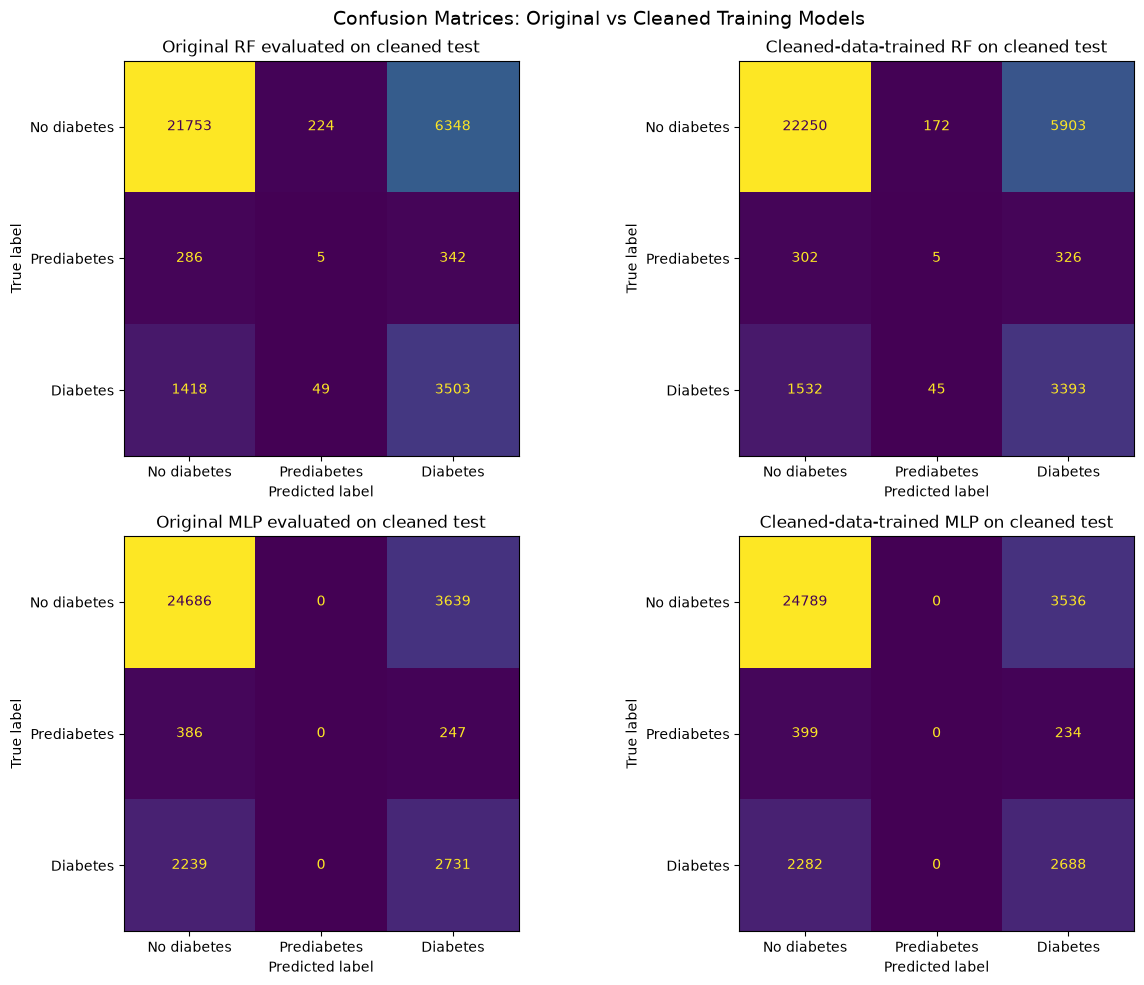

In [18]:
matrix_names = [
    "Original RF evaluated on cleaned test",
    "Cleaned-data-trained RF on cleaned test",
    "Original MLP evaluated on cleaned test",
    "Cleaned-data-trained MLP on cleaned test",
]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, name in zip(axes.flatten(), matrix_names):
    cm = confusion_matrix(
        y_test_dedup, test_predictions[name], labels=CLASS_LABELS
    )
    ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=CLASS_NAMES
    ).plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(name)

plt.suptitle("Confusion Matrices: Original vs Cleaned Training Models", fontsize=14)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "deduplication_confusion_matrices.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

The confusion matrices show that both MLP models failed to predict any prediabetes cases. The Random Forest models correctly identified only five prediabetes cases each on the cleaned test set. Cleaning slightly changed the number of correct no-diabetes predictions and diabetes predictions, but did not meaningfully improve prediabetes detection. The MLP continued to classify prediabetes cases as either no diabetes or diabetes. These results confirm that the main challenge is distinguishing the minority class, rather than simply removing repeated records.

## Compare ROC and precision recall curves

ROC-AUC measures how well probability scores rank each class against the others across thresholds. Precision recall curves are especially important for prediabetes because it is rare. Compare the original models and models retrained after data cleaning using probabilities from the same cleaned test examples. Average precision should be interpreted relative to class prevalence.


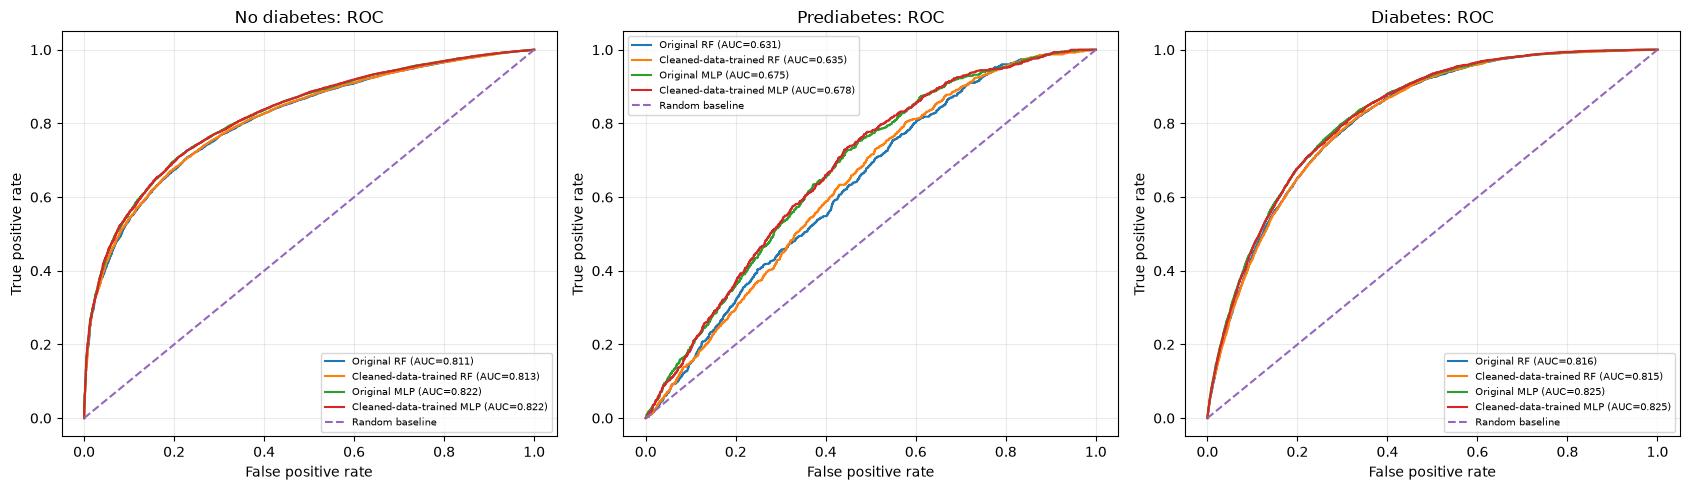

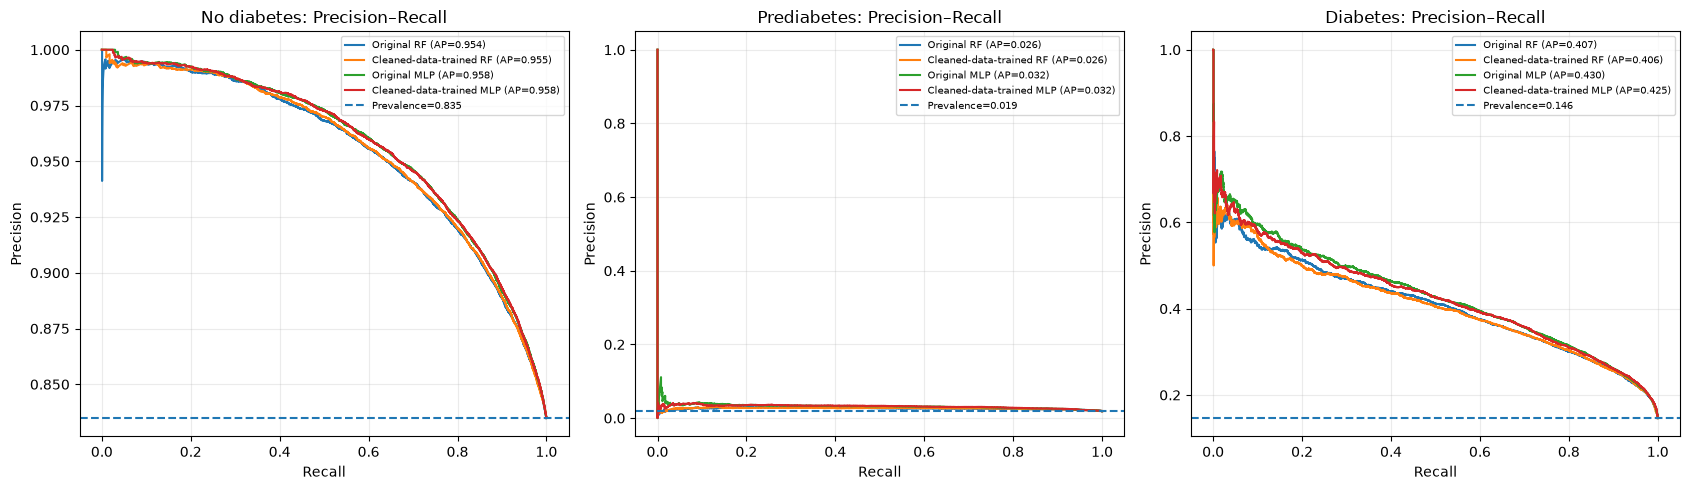

Sensitivity-analysis plots saved to: /home/janviere-munezero/Documents/ML/Introduction to ML/diabetes-risk-prediction/results_deduplication


In [19]:
curve_specs = {
    "Original RF": original_rf_prob,
    "Cleaned-data-trained RF": rf_dedup_test_prob,
    "Original MLP": original_mlp_prob,
    "Cleaned-data-trained MLP": mlp_dedup_test_prob,
}
y_test_binary = label_binarize(np.asarray(y_test_dedup).astype(int), classes=CLASS_LABELS)

# ROC curves
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for class_idx, ax in enumerate(axes):
    for name, probabilities in curve_specs.items():
        fpr, tpr, _ = roc_curve(y_test_binary[:, class_idx], probabilities[:, class_idx])
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
    ax.set_title(f"{CLASS_NAMES[class_idx]}: ROC")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "deduplication_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Precision-recall curves
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for class_idx, ax in enumerate(axes):
    prevalence = y_test_binary[:, class_idx].mean()
    for name, probabilities in curve_specs.items():
        precision, recall, _ = precision_recall_curve(
            y_test_binary[:, class_idx], probabilities[:, class_idx]
        )
        ap = average_precision_score(y_test_binary[:, class_idx], probabilities[:, class_idx])
        ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
    ax.axhline(prevalence, linestyle="--", label=f"Prevalence={prevalence:.3f}")
    ax.set_title(f"{CLASS_NAMES[class_idx]}: Precision–Recall")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "deduplication_precision_recall_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print("Sensitivity-analysis plots saved to:", RESULTS_DIR.resolve())

The ROC curves show that the MLP models generally ranked cases better than the Random Forest models. For prediabetes, ROC-AUC increased slightly from 0.631 to 0.635 for the Random Forest and from approximately 0.675 to 0.678 for the MLP after cleaning. However, these small improvements did not translate into correct prediabetes predictions at the default decision threshold. This demonstrates that a model can distinguish cases to some extent by probability scores while still failing to classify them correctly. Overall, cleaning produced minor changes in class discrimination but did not solve the prediabetes detection problem.

## Conclusion

Removing conflicting label predictor patterns eliminated **6,120 records**, and removing exact duplicates afterward eliminated another **21,486 rows**. Overall, the dataset decreased from 253,680 to 226,074 records. After cleaning, the class distribution changed from 84.24% to 83.27% for no diabetes, from 1.83% to 1.90% for prediabetes, and from 13.93% to 14.83% for diabetes.

On the cleaned test set, the Random Forest's macro F1 improved from 0.4377 to 0.4419 after retraining on cleaned data. The MLP's macro F1 changed only slightly, from 0.4529 to 0.4530. Validation macro F1 decreased slightly for both cleaned-data-trained models compared with their original experiments, although the validation partitions differed after cleaning.

Prediabetes detection remained weak. Random Forest recall stayed at 0.79%, while precision increased slightly from 1.80% to 2.25%. Its false-positive prediabetes predictions decreased from 273 to 217. The MLP continued to predict no prediabetes cases, missing all actual cases.

Overall, cleaning produced limited improvements and did not solve the minority class problem. Removing conflicting-label patterns may also discard genuine respondents. These findings support further investigation into class imbalance and evaluation on more representative data.